In [1]:
from ultralytics import YOLO
import json

def full_evaluation(model_path, data_yaml, output_json):
    model = YOLO(model_path)
    metrics = model.val(data=data_yaml)
    
    # Verificar qué atributos están disponibles
    print("Atributos disponibles en metrics.box:", dir(metrics.box))
    print("Atributos disponibles en metrics.seg:", dir(metrics.seg))
    
    report = {
        'model': model_path,
        'data': data_yaml,
        'box': {
            'map50': float(metrics.box.map50),
            'map75': float(metrics.box.map75) if hasattr(metrics.box, 'map75') else None,
            'map50_95': float(metrics.box.map),
        },
        'segmentation': {
            'map50': float(metrics.seg.map50),
            'map75': float(metrics.seg.map75) if hasattr(metrics.seg, 'map75') else None,
            'map50_95': float(metrics.seg.map),
        },
        'per_class': {}
    }
    
    # Iterar sobre las clases usando metrics.names
    for i, name in metrics.names.items():
        # Usar class_result(i) para obtener métricas específicas de la clase
        try:
            # Intentar obtener métricas por clase
            box_map50 = float(metrics.box.maps50[i]) if hasattr(metrics.box, 'maps50') else None
            seg_map50 = float(metrics.seg.maps50[i]) if hasattr(metrics.seg, 'maps50') else None
            
            report['per_class'][name] = {
                'class_id': i,
                'box_map50': box_map50,
                'seg_map50': seg_map50,
            }
        except Exception as e:
            print(f"Advertencia: No se pudieron obtener métricas para clase {name}: {e}")
            report['per_class'][name] = {
                'class_id': i,
                'error': str(e)
            }
    
    # Guardar resultados
    with open(output_json, 'w') as f:
        json.dump(report, f, indent=2)
    
    return report

# Ejecutar
RAW_DATA_DIR = '/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/'

out = 'scripts/inference/'

model_path = RAW_DATA_DIR + 'notebooks/runs/segment/YOLO-lci1/yolo11x-1280r896-ovl256-w_bgs/weights/best.pt'
dataset_path = RAW_DATA_DIR + 'data/processed/YOLO-1280x1280-256ovlp_w_bgs/dataset.yaml'
output_path = RAW_DATA_DIR + out + 'evaluation_YOLO-1280x1280-256ovlp_w_bgs.json'

report = full_evaluation(model_path, dataset_path, output_path)
print(f"\nResultados guardados en: {output_path}")
print(json.dumps(report, indent=2))

Ultralytics 8.4.13 🚀 Python-3.10.19 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3080 Ti, 12042MiB)
YOLO11x-seg summary (fused): 204 layers, 62,005,593 parameters, 0 gradients, 295.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6692.7±916.2 MB/s, size: 324.7 KB)
val: Scanning /media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/processed/YOLO-1280x1280-256ovlp/labels/val.cache... 459 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 459/459 120.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 29/29 1.6it/s 18.5s0.6s
                   all        459       1220      0.809      0.617      0.647      0.476      0.806      0.586      0.616      0.392
               Decidua        257        405      0.836      0.502      0.555      0.383      0.793      0.443      0.475      0.239
             Labyrinth        334        410      0.859        0.8

In [2]:
"""
Script de evaluación completa para YOLO Instance Segmentation.
Incluye métricas de Ultralytics + métricas personalizadas pixel-level.
"""

from ultralytics import YOLO
import numpy as np
import json
import cv2
from pathlib import Path
from collections import defaultdict
import yaml


def calculate_iou_pixel_level(pred_mask, gt_mask):
    """Calcula IoU a nivel de píxeles entre dos máscaras binarias."""
    intersection = np.logical_and(pred_mask, gt_mask).sum()
    union = np.logical_or(pred_mask, gt_mask).sum()
    return float(intersection / union) if union > 0 else 0.0


def calculate_dice(pred_mask, gt_mask):
    """Calcula Dice coefficient (F1-Score) entre dos máscaras binarias."""
    intersection = np.logical_and(pred_mask, gt_mask).sum()
    pred_sum = pred_mask.sum()
    gt_sum = gt_mask.sum()
    return float(2. * intersection / (pred_sum + gt_sum)) if (pred_sum + gt_sum) > 0 else 0.0


def calculate_pixel_metrics(pred_mask, gt_mask):
    """
    Calcula métricas a nivel de píxel:
    - Precision
    - Recall  
    - Pixel Accuracy
    - Specificity
    - F1-Score
    """
    tp = int(np.logical_and(pred_mask == 1, gt_mask == 1).sum())
    fp = int(np.logical_and(pred_mask == 1, gt_mask == 0).sum())
    fn = int(np.logical_and(pred_mask == 0, gt_mask == 1).sum())
    tn = int(np.logical_and(pred_mask == 0, gt_mask == 0).sum())
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    pixel_acc = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else 0.0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
    
    return {
        'precision': float(precision),
        'recall': float(recall),
        'pixel_accuracy': float(pixel_acc),
        'specificity': float(specificity),
        'f1_score': float(f1),
        'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn
    }


def parse_yolo_segmentation_label(label_path, img_height, img_width):
    """
    Parsea un archivo de etiquetas YOLO de segmentación y devuelve máscaras por clase.
    """
    masks_by_class = defaultdict(lambda: np.zeros((img_height, img_width), dtype=np.uint8))
    
    if not label_path.exists():
        return masks_by_class
    
    with open(label_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue
            
            class_id = int(parts[0])
            coords = list(map(float, parts[1:]))
            
            points = []
            for i in range(0, len(coords), 2):
                x = int(coords[i] * img_width)
                y = int(coords[i+1] * img_height)
                points.append([x, y])
            
            if len(points) >= 3:
                points = np.array(points, np.int32)
                cv2.fillPoly(masks_by_class[class_id], [points], 1)
    
    return masks_by_class


def calculate_custom_metrics_on_validation_set(model, data_yaml, conf_thresh=0.3, max_images=None):
    """
    Calcula métricas pixel-level personalizadas procesando el dataset de validación.
    """
    # Cargar configuración del dataset
    with open(data_yaml, 'r') as f:
        dataset_config = yaml.safe_load(f)
    
    base_path = Path(data_yaml).parent

    val_images_path = base_path / 'images' / 'val'
    val_labels_path = base_path / 'labels' / 'val'

    
    if not val_images_path.exists():
        print(f"  ⚠ No se encontró carpeta de validación: {val_images_path}")
        return None
    
    # Obtener clases
    names = dataset_config.get('names', {})
    if isinstance(names, list):
        names = {i: name for i, name in enumerate(names)}
    
    # Inicializar acumuladores
    global_metrics = {
        'ious': [], 'dices': [],
        'precisions': [], 'recalls': [],
        'pixel_accs': [], 'f1s': [],
        'specificities': []
    }
    
    image_files = list(val_images_path.glob('*.jpg')) + \
                  list(val_images_path.glob('*.png')) + \
                  list(val_images_path.glob('*.jpeg'))
    
    if max_images:
        image_files = image_files[:max_images]
    
    print(f"  Procesando {len(image_files)} imágenes de validación...")
    
    for idx, img_path in enumerate(image_files):
        if idx % 10 == 0:
            print(f"    Progreso: {idx}/{len(image_files)} imágenes...")
        
        # Cargar imagen
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        
        h, w = img.shape[:2]
        
        # Cargar ground truth
        label_path = val_labels_path / f"{img_path.stem}.txt"
        gt_mask = np.zeros((h, w), dtype=np.uint8)
        
        masks_by_class = parse_yolo_segmentation_label(label_path, h, w)
        # Combinar todas las clases en una sola máscara binaria
        for class_id, mask in masks_by_class.items():
            gt_mask = np.logical_or(gt_mask, mask).astype(np.uint8)
        
        # Realizar predicción
        results = model.predict(img, conf=conf_thresh, verbose=False)[0]
        
        # Crear máscara de predicción
        pred_mask = np.zeros((h, w), dtype=np.uint8)
        if results.masks is not None:
            for mask in results.masks.data:
                mask_np = mask.cpu().numpy()
                mask_resized = cv2.resize(mask_np, (w, h), interpolation=cv2.INTER_LINEAR)
                mask_binary = (mask_resized > 0.5).astype(np.uint8)
                pred_mask = np.logical_or(pred_mask, mask_binary).astype(np.uint8)
        
        # Calcular métricas para esta imagen
        if gt_mask.sum() > 0 or pred_mask.sum() > 0:
            iou = calculate_iou_pixel_level(pred_mask, gt_mask)
            dice = calculate_dice(pred_mask, gt_mask)
            pixel_met = calculate_pixel_metrics(pred_mask, gt_mask)
            
            global_metrics['ious'].append(iou)
            global_metrics['dices'].append(dice)
            global_metrics['precisions'].append(pixel_met['precision'])
            global_metrics['recalls'].append(pixel_met['recall'])
            global_metrics['pixel_accs'].append(pixel_met['pixel_accuracy'])
            global_metrics['f1s'].append(pixel_met['f1_score'])
            global_metrics['specificities'].append(pixel_met['specificity'])
    
    # Calcular promedios y estadísticas
    def safe_mean(lst):
        return float(np.mean(lst)) if lst else 0.0
    
    def safe_std(lst):
        return float(np.std(lst)) if lst else 0.0
    
    result = {
        'global': {
            'mean_iou': safe_mean(global_metrics['ious']),
            'std_iou': safe_std(global_metrics['ious']),
            'mean_dice': safe_mean(global_metrics['dices']),
            'std_dice': safe_std(global_metrics['dices']),
            'mean_precision': safe_mean(global_metrics['precisions']),
            'std_precision': safe_std(global_metrics['precisions']),
            'mean_recall': safe_mean(global_metrics['recalls']),
            'std_recall': safe_std(global_metrics['recalls']),
            'mean_pixel_accuracy': safe_mean(global_metrics['pixel_accs']),
            'std_pixel_accuracy': safe_std(global_metrics['pixel_accs']),
            'mean_f1': safe_mean(global_metrics['f1s']),
            'std_f1': safe_std(global_metrics['f1s']),
            'mean_specificity': safe_mean(global_metrics['specificities']),
            'std_specificity': safe_std(global_metrics['specificities']),
            'num_images_evaluated': len(image_files),
        },
        'per_image': {
            'iou_values': global_metrics['ious'],
            'dice_values': global_metrics['dices'],
            'precision_values': global_metrics['precisions'],
            'recall_values': global_metrics['recalls'],
        }
    }
    
    return result


def get_per_class_metrics(metrics):
    """
    Extrae métricas por clase de diferentes fuentes posibles en Ultralytics.
    """
    per_class = {}
    names = metrics.names if hasattr(metrics, 'names') else {}
    
    # Intento 1: Desde results_dict (formato más nuevo)
    if hasattr(metrics, 'results_dict') and metrics.results_dict:
        for i, name in names.items():
            class_data = {'class_id': i}
            # Buscar claves que contengan el nombre de la clase
            for key, value in metrics.results_dict.items():
                if name in key:
                    metric_name = key.replace(f"{name}_", "")
                    class_data[metric_name] = float(value)
            if len(class_data) > 1:
                per_class[name] = class_data
    
    # Intento 2: Desde box.ap y seg.ap (arrays de AP por clase)
    if not per_class and hasattr(metrics.box, 'ap'):
        for i, name in names.items():
            try:
                box_ap = metrics.box.ap[i] if i < len(metrics.box.ap) else None
                seg_ap = metrics.seg.ap[i] if hasattr(metrics.seg, 'ap') and i < len(metrics.seg.ap) else None
                
                box_ap50 = metrics.box.ap50[i] if hasattr(metrics.box, 'ap50') and i < len(metrics.box.ap50) else None
                seg_ap50 = metrics.seg.ap50[i] if hasattr(metrics.seg, 'ap50') and i < len(metrics.seg.ap50) else None
                
                per_class[name] = {
                    'class_id': i,
                    'box_ap': float(box_ap) if box_ap is not None else None,
                    'box_ap50': float(box_ap50) if box_ap50 is not None else None,
                    'seg_ap': float(seg_ap) if seg_ap is not None else None,
                    'seg_ap50': float(seg_ap50) if seg_ap50 is not None else None,
                }
            except Exception as e:
                pass
    
    # Intento 3: Usar class_result()
    if not per_class:
        for i, name in names.items():
            try:
                result = metrics.class_result(i)
                if result and len(result) >= 4:
                    per_class[name] = {
                        'class_id': i,
                        'precision': float(result[0]),
                        'recall': float(result[1]),
                        'ap50': float(result[2]),
                        'ap': float(result[3]),
                    }
            except:
                pass
    
    return per_class


def full_evaluation_with_custom_metrics(model_path, data_yaml, output_json, conf_thresh=0.3, max_images=None):
    """
    Evaluación completa con métricas de Ultralytics + métricas personalizadas pixel-level.
    """
    print(f"Cargando modelo: {model_path}")
    model = YOLO(model_path)
    
    print(f"\n{'='*60}")
    print("FASE 1: Métricas Ultralytics (validación estándar)")
    print(f"{'='*60}")
    print(f"Ejecutando validación con conf={conf_thresh}...")
    
    metrics = model.val(data=data_yaml, conf=conf_thresh)
    
    # ============ MÉTRICAS ULTRALYTICS (Globales) ============
    report = {
        'model': model_path,
        'data': data_yaml,
        'conf_threshold': conf_thresh,
        'ultralytics_global': {
            'box': {
                'map50': float(metrics.box.map50),
                'map': float(metrics.box.map),
            },
            'segmentation': {
                'map50': float(metrics.seg.map50),
                'map': float(metrics.seg.map),
            },
            'speed': metrics.speed,
        }
    }
    
    # ============ MÉTRICAS POR CLASE ============
    print("\nExtrayendo métricas por clase...")
    per_class = get_per_class_metrics(metrics)
    report['per_class'] = per_class
    
    if per_class:
        print(f"✓ Métricas por clase extraídas para {len(per_class)} clases")
        for name, data in per_class.items():
            print(f"  - {name}: {data}")
    else:
        print("⚠ No se pudieron extraer métricas por clase")
        report['per_class'] = {name: {'class_id': i, 'note': 'No metrics available'} 
                               for i, name in metrics.names.items()}
    
    # ============ MÉTRICAS PERSONALIZADAS PIXEL-LEVEL ============
    print(f"\n{'='*60}")
    print("FASE 2: Métricas personalizadas pixel-level")
    print(f"{'='*60}")
    print("(Esto requiere re-procesar las imágenes de validación)")
    
    custom_metrics = calculate_custom_metrics_on_validation_set(
        model, data_yaml, conf_thresh, max_images
    )
    report['custom_pixel_metrics'] = custom_metrics
    
    # Guardar resultados
    with open(output_json, 'w') as f:
        json.dump(report, f, indent=2)
    
    print(f"\n✓ Resultados guardados en: {output_json}")
    return report


def print_summary(report):
    """Imprime un resumen formateado de las métricas."""
    print(f"\n{'='*60}")
    print("RESUMEN DE MÉTRICAS")
    print(f"{'='*60}")
    
    print(f"\n📊 MÉTRICAS ULTRALYTICS:")
    print(f"  Box mAP50:     {report['ultralytics_global']['box']['map50']:.4f}")
    print(f"  Box mAP50-95:  {report['ultralytics_global']['box']['map']:.4f}")
    print(f"  Seg mAP50:     {report['ultralytics_global']['segmentation']['map50']:.4f}")
    print(f"  Seg mAP50-95:  {report['ultralytics_global']['segmentation']['map']:.4f}")
    
    if report.get('per_class'):
        print(f"\n📋 MÉTRICAS POR CLASE:")
        for name, data in report['per_class'].items():
            if 'ap50' in data:
                print(f"  {name}: AP50={data['ap50']:.4f}, AP={data['ap']:.4f}")
            elif 'seg_ap50' in data:
                print(f"  {name}: Seg_AP50={data['seg_ap50']:.4f}")
    
    if report.get('custom_pixel_metrics'):
        cm = report['custom_pixel_metrics']['global']
        print(f"\n🔬 MÉTRICAS PERSONALIZADAS (Pixel-Level):")
        print(f"  Mean IoU:            {cm['mean_iou']:.4f} (±{cm['std_iou']:.4f})")
        print(f"  Mean Dice:           {cm['mean_dice']:.4f} (±{cm['std_dice']:.4f})")
        print(f"  Mean Precision:      {cm['mean_precision']:.4f} (±{cm['std_precision']:.4f})")
        print(f"  Mean Recall:         {cm['mean_recall']:.4f} (±{cm['std_recall']:.4f})")
        print(f"  Mean Pixel Accuracy: {cm['mean_pixel_accuracy']:.4f} (±{cm['std_pixel_accuracy']:.4f})")
        print(f"  Mean F1:             {cm['mean_f1']:.4f} (±{cm['std_f1']:.4f})")
        print(f"  Mean Specificity:    {cm['mean_specificity']:.4f} (±{cm['std_specificity']:.4f})")
        print(f"  Imágenes evaluadas:  {cm['num_images_evaluated']}")




In [3]:
RAW_DATA_DIR = '/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/'

out = 'scripts/inference/'

model_path = RAW_DATA_DIR + 'notebooks/runs/segment/YOLO-lci1/yolo11x-1280r896-ovl256-w_bgs/weights/best.pt'
dataset_path = RAW_DATA_DIR + 'data/processed/YOLO-1280x1280-256ovlp_w_bgs/dataset.yaml'
output_path = RAW_DATA_DIR + out + 'evaluation_YOLO-1280x1280-256ovlp_w_bgs.json'

# Parámetros
conf_thresh = 0.3
max_images = None  # Pon un número (ej: 50) para probar con menos imágenes primero

# Ejecutar evaluación
report = full_evaluation_with_custom_metrics(
    model_path, 
    dataset_path, 
    output_path, 
    conf_thresh=conf_thresh,
    max_images=max_images
)

# Mostrar resumen
print_summary(report)

Cargando modelo: /media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/notebooks/runs/segment/YOLO-lci1/yolo11x-1280r896-ovl256-w_bgs/weights/best.pt

FASE 1: Métricas Ultralytics (validación estándar)
Ejecutando validación con conf=0.3...
Ultralytics 8.4.13 🚀 Python-3.10.19 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3080 Ti, 12042MiB)
YOLO11x-seg summary (fused): 204 layers, 62,005,593 parameters, 0 gradients, 295.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 8696.5±750.8 MB/s, size: 676.6 KB)
val: Scanning /media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/processed/YOLO-1280x1280-256ovlp/labels/val.cache... 459 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 459/459 128.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 29/29 1.6it/s 18.1s0.6s
                   all        459       1220      0.809      0.617      0.729    

# Visualización de resultados

Guardado: comparacion_modelos.png


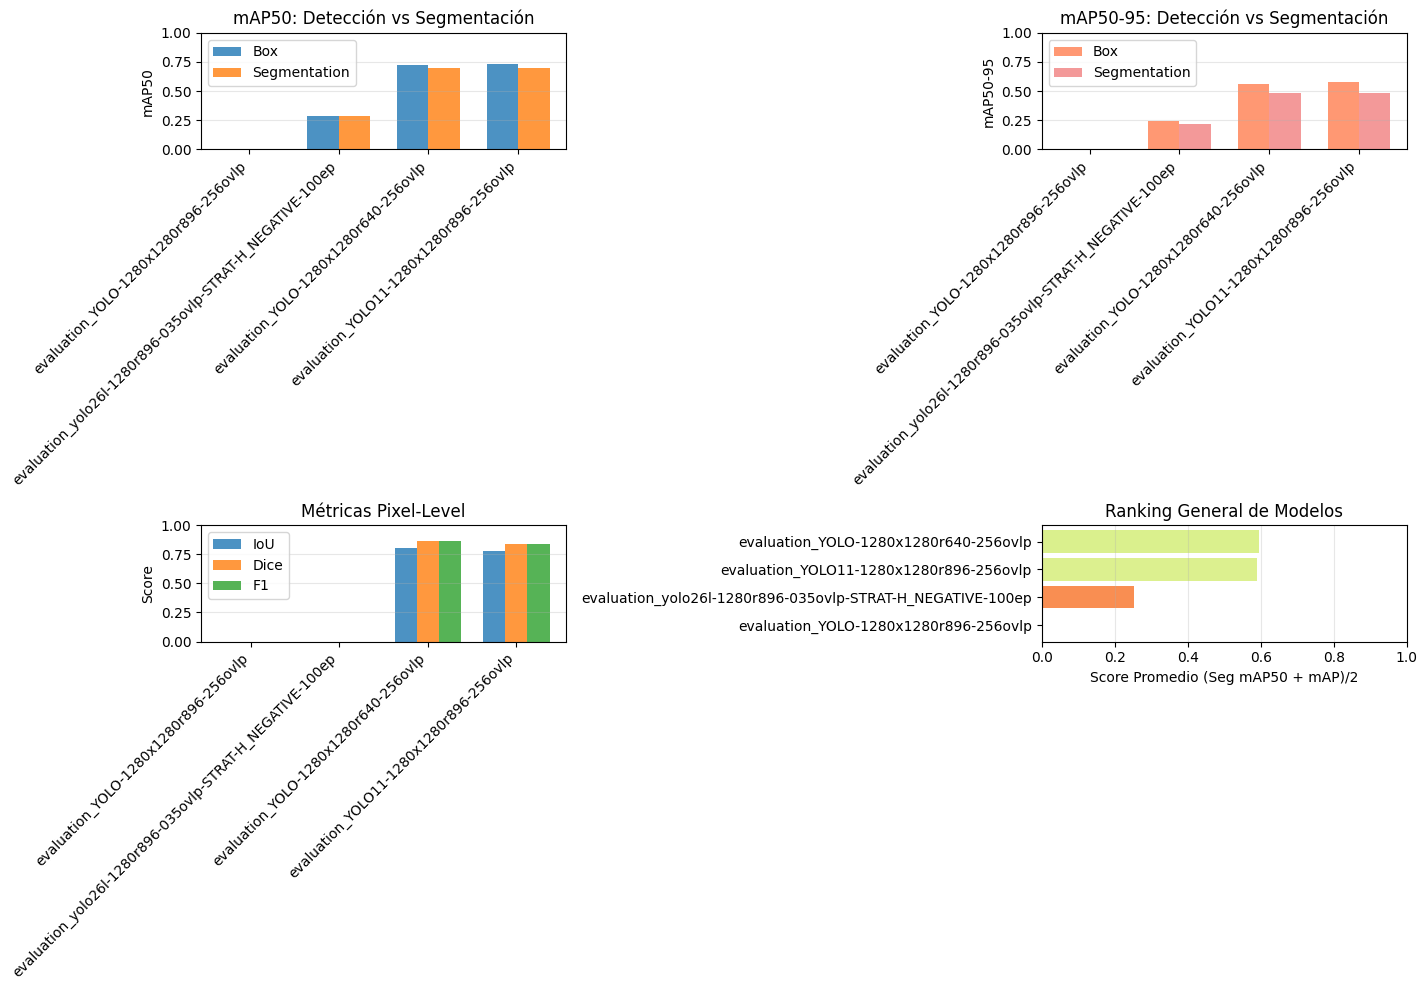


TABLA COMPARATIVA
                                                    modelo  box_map50  box_map  seg_map50  seg_map  pixel_iou  pixel_dice  pixel_f1  score_promedio
                     evaluation_YOLO-1280x1280r896-256ovlp     0.0000   0.0000     0.0000   0.0000     0.0000      0.0000    0.0000          0.0000
evaluation_yolo26l-1280r896-035ovlp-STRAT-H_NEGATIVE-100ep     0.2887   0.2443     0.2872   0.2167        NaN         NaN       NaN          0.2520
                     evaluation_YOLO-1280x1280r640-256ovlp     0.7240   0.5566     0.7022   0.4866     0.8046      0.8597    0.8597          0.5944
                   evaluation_YOLO11-1280x1280r896-256ovlp     0.7289   0.5757     0.6997   0.4810     0.7801      0.8347    0.8347          0.5904

🏆 Mejor Segmentación mAP50: evaluation_YOLO-1280x1280r640-256ovlp
🏆 Mejor Segmentación mAP50-95: evaluation_YOLO-1280x1280r640-256ovlp

Guardado: tabla_comparativa.csv


In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path


def cargar_resultados(directorio_resultados):
    """
    Carga todos los archivos JSON de resultados.
    """
    resultados = []
    
    for json_file in Path(directorio_resultados).glob("*.json"):
        with open(json_file) as f:
            data = json.load(f)
        
        # Extraer nombre del modelo del archivo
        nombre = json_file.stem.replace("eval_", "")
        
        # Extraer métricas clave
        resumen = {
            'modelo': nombre,
            'box_map50': data['ultralytics_global']['box']['map50'],
            'box_map': data['ultralytics_global']['box']['map'],
            'seg_map50': data['ultralytics_global']['segmentation']['map50'],
            'seg_map': data['ultralytics_global']['segmentation']['map'],
        }
        
        # Agregar métricas personalizadas si existen
        if data.get('custom_pixel_metrics'):
            cm = data['custom_pixel_metrics']['global']
            resumen['pixel_iou'] = cm.get('mean_iou', 0)
            resumen['pixel_dice'] = cm.get('mean_dice', 0)
            resumen['pixel_f1'] = cm.get('mean_f1', 0)
        
        resultados.append(resumen)
    
    return pd.DataFrame(resultados)


def graficar_comparacion(df, guardar_en='comparacion_modelos.png'):
    """
    Gráfico de barras comparando todos los modelos.
    """
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # 1. mAP50 Box vs Seg
    ax = axes[0, 0]
    x = np.arange(len(df))
    width = 0.35
    ax.bar(x - width/2, df['box_map50'], width, label='Box', alpha=0.8)
    ax.bar(x + width/2, df['seg_map50'], width, label='Segmentation', alpha=0.8)
    ax.set_ylabel('mAP50')
    ax.set_title('mAP50: Detección vs Segmentación')
    ax.set_xticks(x)
    ax.set_xticklabels(df['modelo'], rotation=45, ha='right')
    ax.legend()
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=0.3)
    
    # 2. mAP50-95 Box vs Seg
    ax = axes[0, 1]
    ax.bar(x - width/2, df['box_map'], width, label='Box', alpha=0.8, color='coral')
    ax.bar(x + width/2, df['seg_map'], width, label='Segmentation', alpha=0.8, color='lightcoral')
    ax.set_ylabel('mAP50-95')
    ax.set_title('mAP50-95: Detección vs Segmentación')
    ax.set_xticks(x)
    ax.set_xticklabels(df['modelo'], rotation=45, ha='right')
    ax.legend()
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=0.3)
    
    # 3. Métricas pixel-level (si existen)
    ax = axes[1, 0]
    if 'pixel_iou' in df.columns:
        metrics = ['pixel_iou', 'pixel_dice', 'pixel_f1']
        labels = ['IoU', 'Dice', 'F1']
        x_pos = np.arange(len(df))
        
        for i, (metric, label) in enumerate(zip(metrics, labels)):
            ax.bar(x_pos + i*0.25, df[metric], 0.25, label=label, alpha=0.8)
        
        ax.set_ylabel('Score')
        ax.set_title('Métricas Pixel-Level')
        ax.set_xticks(x_pos + 0.25)
        ax.set_xticklabels(df['modelo'], rotation=45, ha='right')
        ax.legend()
        ax.set_ylim(0, 1)
        ax.grid(axis='y', alpha=0.3)
    else:
        ax.text(0.5, 0.5, 'No hay métricas\npixel-level', 
                ha='center', va='center', transform=ax.transAxes)
        ax.set_title('Métricas Pixel-Level')
    
    # 4. Ranking general
    ax = axes[1, 1]
    # Score promedio de todas las métricas
    df['score_promedio'] = df[['seg_map50', 'seg_map']].mean(axis=1)
    df_sorted = df.sort_values('score_promedio', ascending=True)
    
    colors = plt.cm.RdYlGn(df_sorted['score_promedio'])
    ax.barh(df_sorted['modelo'], df_sorted['score_promedio'], color=colors)
    ax.set_xlabel('Score Promedio (Seg mAP50 + mAP)/2')
    ax.set_title('Ranking General de Modelos')
    ax.set_xlim(0, 1)
    ax.grid(axis='x', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(guardar_en, dpi=150, bbox_inches='tight')
    print(f"Guardado: {guardar_en}")
    plt.show()


def tabla_comparativa(df, guardar_en='tabla_comparativa.csv'):
    """
    Genera tabla formateada con mejor modelo destacado.
    """
    # Encontrar mejores
    mejor_seg50 = df.loc[df['seg_map50'].idxmax(), 'modelo']
    mejor_seg = df.loc[df['seg_map'].idxmax(), 'modelo']
    
    # Formatear con colores (para consola)
    print(f"\n{'='*70}")
    print("TABLA COMPARATIVA")
    print(f"{'='*70}")
    print(df.to_string(index=False, float_format='%.4f'))
    print(f"\n{'='*70}")
    print(f"🏆 Mejor Segmentación mAP50: {mejor_seg50}")
    print(f"🏆 Mejor Segmentación mAP50-95: {mejor_seg}")
    print(f"{'='*70}")
    
    # Guardar CSV
    df.to_csv(guardar_en, index=False, float_format='%.4f')
    print(f"\nGuardado: {guardar_en}")


# USO
if __name__ == "__main__":
    # Cargar todos los resultados
    df = cargar_resultados("/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/models/evaluation/")
    
    # Generar visualizaciones
    graficar_comparacion(df, "comparacion_modelos.png")
    tabla_comparativa(df, "tabla_comparativa.csv")